# Exploratory Data Analysis — FeTA Dataset

This notebook explores the Fetal Tissue Annotation (FeTA) dataset.

Objectives:
- Understand the dataset organization.
- Inspect MRI volumes and segmentation masks.
- Analyze image dimensions, voxel spacing, and tissue labels.
- Visualize fetal brain MRI scans.
- Identify potential preprocessing requirements.

In [1]:

from pathlib import Path
from collections import Counter
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib

# Locate the project root
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Import shared utility functions
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
    
from src.data_utils import (
    find_subjects,
    load_nifti,
    inspect_volume,
    count_segmentation_labels,
    check_volume_quality,
)
# Dataset path
DATA_DIR = PROJECT_ROOT / "data" / "FeTA" / "feta_2.4"

# Check dataset availability
print("Dataset exists:", DATA_DIR.exists())

# Find subject directories
subjects = find_subjects(DATA_DIR)

print("Number of subjects:", len(subjects))
print("First 5 subjects:", [s.name for s in subjects[:5]])


Dataset exists: True
Number of subjects: 80
First 5 subjects: ['sub-001', 'sub-002', 'sub-003', 'sub-004', 'sub-005']



## 1. Dataset Structure

### 1.1 MRI Volumes and Segmentation Masks

The FeTA dataset contains 3D fetal brain MRI volumes and their corresponding segmentation masks.

**Objectives:**
- Count the available MRI volumes (`T2w`).
- Count the corresponding segmentation masks (`dseg`).
- Identify the different MRI reconstruction methods.
- Check whether each MRI has a corresponding segmentation mask.

**Why is this important?**

Having 80 subject folders does not necessarily mean having 80 labelled MRI volumes. Some subjects may have multiple reconstructions or missing segmentation masks.

We need to identify valid MRI–segmentation pairs before preparing our training dataset.


In [2]:

# Find MRI volumes and segmentation masks
mri_files = sorted(DATA_DIR.glob("sub-*/anat/*_T2w.nii.gz"))
seg_files = sorted(DATA_DIR.glob("sub-*/anat/*_dseg.nii.gz"))

print("Number of MRI volumes:", len(mri_files))
print("Number of segmentation masks:", len(seg_files))

# Count reconstruction methods
reconstruction_methods = Counter(
    path.name.split("_rec-")[1].split("_")[0]
    for path in mri_files
    if "_rec-" in path.name
)

print("\nReconstruction methods:")
for method, count in sorted(reconstruction_methods.items()):
    print(f"  {method}: {count}")

# Check MRI–segmentation pairs
missing_masks = []

for mri_path in mri_files:
    seg_path = mri_path.with_name(
        mri_path.name.replace("_T2w.nii.gz", "_dseg.nii.gz")
    )

    if not seg_path.exists():
        missing_masks.append(mri_path)

print("\nMRI volumes without a matching segmentation mask:",
      len(missing_masks))

for path in missing_masks:
    print(path.relative_to(DATA_DIR))


Number of MRI volumes: 80
Number of segmentation masks: 80

Reconstruction methods:
  irtk: 40
  mial: 40

MRI volumes without a matching segmentation mask: 0



### Initial Findings

The FeTA dataset contains:
- 80 subject folders.
- 80 T2-weighted MRI volumes.
- 80 corresponding segmentation masks.
- Two reconstruction methods: IRTK (40 volumes) and MIAL (40 volumes).
- No missing MRI–segmentation pairs based on filenames.

**Next step:** Inspect the MRI dimensions, voxel spacing, orientation, and intensity values to identify potential preprocessing requirements.



## 2. MRI Volume Properties

### 2.1 Inspecting a Single MRI Volume

MRI images are stored as 3D NIfTI volumes (`.nii.gz`).

**Objectives:**
- Load one MRI volume and its segmentation mask.
- Examine their dimensions.
- Inspect voxel spacing and image orientation.
- Check MRI intensity statistics.
- Identify the segmentation labels present.

**Why is this important?**

Neural networks require consistent input representations. Understanding the spatial dimensions, voxel spacing, and intensity ranges helps us determine which preprocessing steps may be necessary.


In [3]:

# Select the first MRI and its corresponding segmentation
mri_path = mri_files[0]
seg_path = mri_path.with_name(
    mri_path.name.replace("_T2w.nii.gz", "_dseg.nii.gz")
)

# Load MRI and segmentation
mri_img, mri = load_nifti(mri_path)
seg_img, seg = load_nifti(seg_path, is_segmentation=True)

# Inspect volume properties
properties = inspect_volume(mri_img, mri)

print("Subject:", mri_path.parent.parent.name)
print("MRI file:", mri_path.name)

print("\nMRI properties:")
for name, value in properties.items():
    print(f"  {name}: {value}")

# Check MRI–segmentation compatibility
print("\nSegmentation shape:", seg.shape)
print("Shapes match:", mri.shape == seg.shape)
print("Affines match:", np.allclose(mri_img.affine, seg_img.affine))

# Inspect segmentation labels
print("Segmentation labels:", np.unique(seg))


Subject: sub-001
MRI file: sub-001_rec-mial_T2w.nii.gz

MRI properties:
  shape: (256, 256, 256)
  voxel_spacing: (np.float32(0.5469), np.float32(0.5469), np.float32(0.5469))
  orientation: ('R', 'A', 'S')
  min: 0.0
  max: 1588.0
  mean: 57.98271942138672
  std: 180.80284118652344

Segmentation shape: (256, 256, 256)
Shapes match: True
Affines match: True
Segmentation labels: [0. 1. 2. 3. 4. 5. 6. 7.]



### 2.2 MRI and Segmentation Visualization

**Objectives:**
- Visualize the MRI volume in three anatomical planes.
- Display the corresponding segmentation masks.
- Overlay the segmentation masks on the MRI.
- Visually verify that the anatomical labels are correctly aligned with the MRI.

**Why is this important?**

Before training a segmentation model, we need to visually inspect the images and their ground-truth annotations to detect potential alignment problems or unexpected segmentation errors.


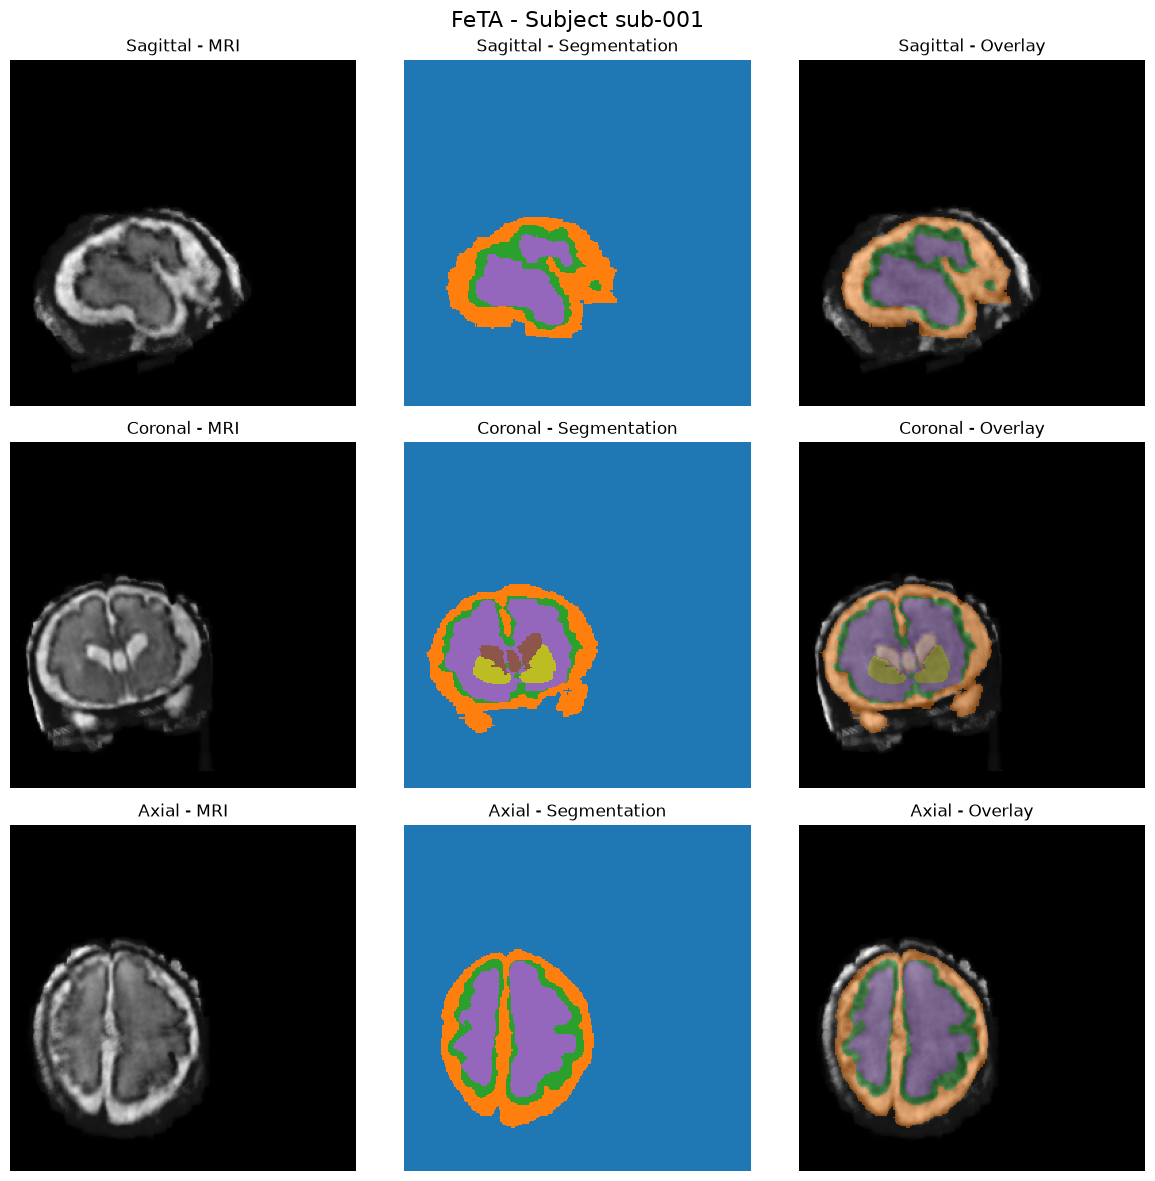

In [4]:

# Select the middle slice along each axis
slice_indices = [dim // 2 for dim in mri.shape]

# Extract MRI and segmentation slices
mri_slices = [
    mri[slice_indices[0], :, :],
    mri[:, slice_indices[1], :],
    mri[:, :, slice_indices[2]]
]

seg_slices = [
    seg[slice_indices[0], :, :],
    seg[:, slice_indices[1], :],
    seg[:, :, slice_indices[2]]
]

# RAS orientation: sagittal, coronal, axial
plane_names = ["Sagittal", "Coronal", "Axial"]

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for i, (mri_slice, seg_slice) in enumerate(zip(mri_slices, seg_slices)):
    # Transpose for consistent display
    mri_slice = mri_slice.T
    seg_slice = seg_slice.T

    # MRI
    axes[i, 0].imshow(mri_slice, cmap="gray", origin="lower")
    axes[i, 0].set_title(f"{plane_names[i]} - MRI")

    # Segmentation
    axes[i, 1].imshow(
        seg_slice, cmap="tab10", vmin=0, vmax=7,
        interpolation="nearest", origin="lower"
    )
    axes[i, 1].set_title(f"{plane_names[i]} - Segmentation")

    # MRI + segmentation overlay
    axes[i, 2].imshow(mri_slice, cmap="gray", origin="lower")
    axes[i, 2].imshow(
        np.ma.masked_where(seg_slice == 0, seg_slice),
        cmap="tab10", vmin=0, vmax=7,
        alpha=0.45, interpolation="nearest", origin="lower"
    )
    axes[i, 2].set_title(f"{plane_names[i]} - Overlay")

    for ax in axes[i]:
        ax.axis("off")

plt.suptitle("FeTA - Subject sub-001", fontsize=16)
plt.tight_layout()
plt.show()



### Visualization Findings — Subject sub-001

The MRI and its corresponding ground-truth segmentation were visualized in three anatomical planes: sagittal, coronal, and axial.

**Observations:**
- The fetal brain is clearly visible in all three planes.
- The segmentation distinguishes multiple anatomical tissue classes.
- The segmentation boundaries appear visually consistent with the MRI anatomy in the selected slices.
- No obvious spatial misalignment was observed in these views.

**Limitations:**
- Only the central slices of one subject were inspected.
- Additional subjects and slices should be examined to identify potential annotation or image-quality issues.
- Visualization colors are arbitrary and do not represent the official FeTA color convention.

**Next step:** Analyze the distribution of tissue labels to identify potential class imbalance.



### 2.3 Segmentation Label Distribution

**Objectives:**
- Count the number of voxels belonging to each segmentation class.
- Calculate the proportion of each class in the MRI volume.
- Visualize the distribution of anatomical labels.
- Identify potential class imbalance.

**Why is this important?**

Brain structures have different sizes. Some tissues occupy large regions, while others occupy relatively few voxels.

This imbalance may affect model training, since larger classes can dominate certain loss functions.

Understanding class frequencies will help us choose appropriate segmentation losses and evaluation metrics.


In [5]:

# FeTA segmentation labels
FETA_LABELS = {
    0: "Background",
    1: "Cerebrospinal fluid",
    2: "Grey matter",
    3: "White matter",
    4: "Ventricles",
    5: "Cerebellum",
    6: "Deep grey matter",
    7: "Brainstem",
}

# Count voxels per class
label_counts = count_segmentation_labels(seg)

# Total number of voxels
total_voxels = seg.size

# Create a summary table
label_df = pd.DataFrame([
    {
        "Label": label,
        "Tissue": name,
        "Voxel count": label_counts.get(label, 0),
        "Percentage (%)": 100 * label_counts.get(label, 0) / total_voxels,
    }
    for label, name in FETA_LABELS.items()
])

display(label_df.round(2))


,Label,Tissue,Voxel count,Percentage (%)
0,0,Background,15390970,91.74
1,1,Cerebrospinal fluid,491324,2.93
2,2,Grey matter,216499,1.29
3,3,White matter,494319,2.95
4,4,Ventricles,65335,0.39
5,5,Cerebellum,33031,0.20
6,6,Deep grey matter,66644,0.40
7,7,Brainstem,19094,0.11


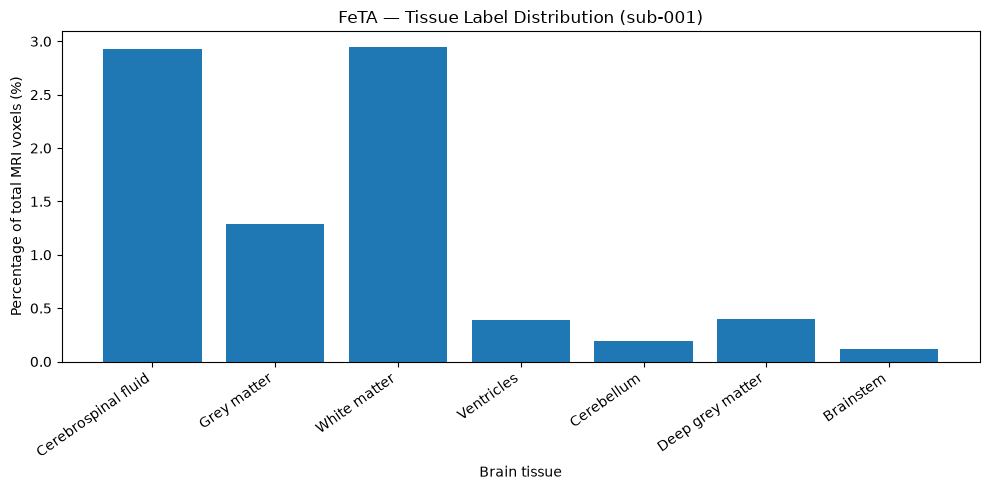

In [6]:

# Exclude background to better compare brain tissues
tissue_df = label_df[label_df["Label"] != 0]

plt.figure(figsize=(10, 5))

plt.bar(
    tissue_df["Tissue"],
    tissue_df["Percentage (%)"]
)

plt.title("FeTA — Tissue Label Distribution (sub-001)")
plt.xlabel("Brain tissue")
plt.ylabel("Percentage of total MRI voxels (%)")

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()



### Findings — Tissue Label Distribution (sub-001)

- White matter and cerebrospinal fluid are the largest foreground classes (~3% each).
- Grey matter represents approximately 1.3% of the volume.
- Brainstem (~0.11%) and cerebellum (~0.20%) are the smallest classes.
- Background occupies approximately 91.74% of the MRI volume.

**Implications:**
- The segmentation task exhibits substantial class imbalance.
- Global voxel accuracy may be misleading.
- Per-class evaluation metrics and imbalance-aware training strategies should be considered.

**Limitation:** These observations concern only `sub-001` and must be verified across the entire dataset.



## 3. Dataset-Wide Analysis

### 3.1 MRI Properties and Data Consistency

After inspecting a single subject, we extend the analysis to all 80 FeTA subjects.

**Objectives:**
- Compare MRI dimensions, voxel spacing, and orientations.
- Verify MRI–segmentation compatibility for every subject.
- Check for unexpected or missing segmentation labels.
- Detect potential data quality issues.
- Identify preprocessing requirements before model training.

**Why is this important?**

A model requires consistent input representations. Dataset-wide checks help identify differences between subjects that may require preprocessing, while ensuring that MRI volumes and segmentation masks are compatible.


In [7]:

# Expected segmentation labels for FeTA
EXPECTED_LABELS = set(range(8))

records = []

for mri_path in mri_files:

    # Find the corresponding segmentation mask
    seg_path = mri_path.with_name(
        mri_path.name.replace("_T2w.nii.gz", "_dseg.nii.gz")
    )

    # Load MRI and segmentation
    mri_img, mri = load_nifti(mri_path)
    seg_img, seg = load_nifti(seg_path, is_segmentation=True)

    # Inspect MRI properties
    properties = inspect_volume(mri_img, mri)

    # Check labels and MRI-mask compatibility
    labels = set(np.unique(seg).tolist())

    records.append({
        "subject": mri_path.parent.parent.name,
        "reconstruction": (
            mri_path.name.split("_rec-")[1].split("_")[0]
        ),
        "shape": properties["shape"],
        "spacing": tuple(float(v) for v in properties["voxel_spacing"]),
        "orientation": properties["orientation"],
        "min_intensity": properties["min"],
        "max_intensity": properties["max"],
        "mean_intensity": properties["mean"],
        "std_intensity": properties["std"],
        "shapes_match": mri.shape == seg.shape,
        "affines_match": np.allclose(mri_img.affine, seg_img.affine, atol=1e-6),
        "labels": sorted(labels),
        "unexpected_labels": sorted(labels - EXPECTED_LABELS),
    })

# Create a summary DataFrame
dataset_df = pd.DataFrame(records)


# Display a compact summary of the first subjects
summary_columns = [
    "subject",
    "reconstruction",
    "shape",
    "spacing",
    "orientation",
    "mean_intensity",
    "shapes_match",
    "affines_match"
]

display(dataset_df[summary_columns].head(10))


,subject,reconstruction,shape,spacing,orientation,mean_intensity,shapes_match,affines_match
0,sub-001,mial,"(256, 256, 256)","(0.5469, 0.5469, 0.5469)","(R, A, S)",57.982719,True,True
1,sub-002,mial,"(256, 256, 256)","(0.4688, 0.4688, 0.4688)","(R, A, S)",100.336105,True,True
2,sub-003,mial,"(256, 256, 256)","(0.5078, 0.5078, 0.5078)","(R, A, S)",63.195488,True,True
3,sub-004,mial,"(256, 256, 256)","(0.5469, 0.5469, 0.5469)","(R, A, S)",23.644146,True,True
4,sub-005,mial,"(256, 256, 256)","(0.4297, 0.4297, 0.4297)","(R, A, S)",50.304012,True,True
5,sub-006,mial,"(256, 256, 256)","(0.5273, 0.5273, 0.5273)","(R, A, S)",52.321205,True,True
6,sub-007,mial,"(256, 256, 256)","(0.4688, 0.4688, 0.4688)","(R, A, S)",36.964828,True,True
7,sub-008,mial,"(256, 256, 256)","(0.4688, 0.4688, 0.4688)","(R, A, S)",28.241442,True,True
8,sub-009,mial,"(256, 256, 256)","(0.4688, 0.4688, 0.4688)","(R, A, S)",160.836792,True,True
9,sub-010,mial,"(256, 256, 256)","(0.4688, 0.4688, 0.4688)","(R, A, S)",86.211380,True,True


In [8]:

print("Total MRI volumes analyzed:", len(dataset_df))

print("\nMRI shapes:")
print(dataset_df["shape"].value_counts())

print("\nVoxel spacings:")
print(dataset_df["spacing"].value_counts())

print("\nMRI orientations:")
print(dataset_df["orientation"].value_counts())

print("\nMRI–segmentation compatibility:")
print("Shape mismatches:", (~dataset_df["shapes_match"]).sum())
print("Affine mismatches:", (~dataset_df["affines_match"]).sum())

print("\nVolumes with unexpected segmentation labels:")
print(dataset_df["unexpected_labels"].apply(bool).sum())

print("\nIntensity statistics:")
display(
    dataset_df[
        ["min_intensity", "max_intensity",
         "mean_intensity", "std_intensity"]
    ].describe().round(2)
)


Total MRI volumes analyzed: 80

MRI shapes:
shape
(256, 256, 256)    80
Name: count, dtype: int64

Voxel spacings:
spacing
(0.5, 0.5, 0.5)             40
(0.4688, 0.4688, 0.4688)    19
(0.5078, 0.5078, 0.5078)     8
(0.5469, 0.5469, 0.5469)     5
(0.5273, 0.5273, 0.5273)     3
(0.5859, 0.5859, 0.5859)     3
(0.4297, 0.4297, 0.4297)     1
(0.7031, 0.7031, 0.7031)     1
Name: count, dtype: int64

MRI orientations:
orientation
(R, A, S)    40
(L, A, S)    40
Name: count, dtype: int64

MRI–segmentation compatibility:
Shape mismatches: 0
Affine mismatches: 0

Volumes with unexpected segmentation labels:
0

Intensity statistics:


,min_intensity,max_intensity,mean_intensity,std_intensity
count,80.0,80.00,80.00,80.00
mean,0.0,962.85,45.40,121.82
std,0.0,421.21,29.60,65.32
min,0.0,499.36,12.31,49.69
25%,0.0,560.76,23.58,67.22
50%,0.0,857.72,34.60,91.95
75%,0.0,1343.00,58.15,178.06
max,0.0,1833.00,160.84,288.35


In [9]:

# Compare image properties by reconstruction method
print("Orientation by reconstruction method:")
display(
    pd.crosstab(
        dataset_df["reconstruction"],
        dataset_df["orientation"].astype(str)
    )
)

print("\nVoxel spacing by reconstruction method:")
display(
    pd.crosstab(
        dataset_df["reconstruction"],
        dataset_df["spacing"].astype(str)
    )
)


Orientation by reconstruction method:


orientation,"('L', 'A', 'S')","('R', 'A', 'S')"
reconstruction,,
irtk,40,0
mial,0,40



Voxel spacing by reconstruction method:


spacing,"(0.42969998717308044, 0.42969998717308044, 0.42969998717308044)","(0.46880000829696655, 0.46880000829696655, 0.46880000829696655)","(0.5, 0.5, 0.5)","(0.5077999830245972, 0.5077999830245972, 0.5077999830245972)","(0.5273000001907349, 0.5273000001907349, 0.5273000001907349)","(0.5468999743461609, 0.5468999743461609, 0.5468999743461609)","(0.5859000086784363, 0.5859000086784363, 0.5859000086784363)","(0.7031000256538391, 0.7031000256538391, 0.7031000256538391)"
reconstruction,,,,,,,,
irtk,0,0,40,0,0,0,0,0
mial,1,19,0,8,3,5,3,1



### Findings — Dataset-Wide MRI Properties

Analysis of the 80 FeTA volumes revealed:

- **Dimensions:** All volumes have a shape of 256 × 256 × 256.
- **Voxel spacing:** All volumes are isotropic, but resolutions vary between 0.43 and 0.70 mm.
- **Orientation:** 40 volumes are RAS (MIAL) and 40 are LAS (IRTK).
- **Reconstruction methods:**
  - **IRTK:** All 40 volumes have 0.5 mm voxel spacing.
  - **MIAL:** All 40 volumes have varying voxel spacing (0.43–0.70 mm).
- **MRI–mask consistency:** All pairs have matching shapes and affine matrices (`atol=1e-6`), with no unexpected labels (0–7).
- **Intensities:** Substantial variability exists across subjects.

**Implications for preprocessing and evaluation:**

- Standardize MRI and segmentation orientations.
- Investigate resampling to a common voxel spacing and intensity normalization.
- Account for reconstruction-specific differences, which may introduce confounding factors in model evaluation.
- Ensure preprocessing is compatible with the pretrained foundation model.

**Next step:** Analyze tissue label distributions across all subjects to investigate class imbalance.



### 3.2 Dataset-Wide Segmentation Label Distribution

**Objectives:**
- Calculate the distribution of segmentation labels across all 80 subjects.
- Identify the most and least represented brain tissues.
- Measure variations in tissue proportions between subjects.
- Compare tissue distributions between MIAL and IRTK reconstructions.

**Why is this important?**

Understanding class imbalance across the entire dataset helps us choose appropriate loss functions, sampling strategies, and evaluation metrics.

Comparing reconstruction groups may also reveal differences that should be considered when designing fair experiments.


In [10]:

# Calculate tissue proportions for each subject
label_records = []

for seg_path in seg_files:
    # Load segmentation
    _, seg = load_nifti(seg_path, is_segmentation=True)

    # Count voxels per label
    counts = count_segmentation_labels(seg)

    # Total volume and foreground voxels
    total_voxels = seg.size
    foreground_voxels = total_voxels - counts.get(0, 0)

    # Extract subject and reconstruction method
    subject = seg_path.parent.parent.name
    reconstruction = seg_path.name.split("_rec-")[1].split("_")[0]

    for label, tissue in FETA_LABELS.items():
        count = counts.get(label, 0)

        label_records.append({
            "subject": subject,
            "reconstruction": reconstruction,
            "label": label,
            "tissue": tissue,
            "voxel_count": count,
            "percentage": 100 * count / total_voxels,
            "foreground_percentage": (
                100 * count / foreground_voxels
                if label != 0 and foreground_voxels > 0
                else np.nan
            ),
        })

# Build dataset-wide label DataFrame
labels_df = pd.DataFrame(label_records)

display(labels_df.head(10))


,subject,reconstruction,label,tissue,voxel_count,percentage,foreground_percentage
0,sub-001,mial,0,Background,15390970,91.737330,NaN
1,sub-001,mial,1,Cerebrospinal fluid,491324,2.928519,35.442771
2,sub-001,mial,2,Grey matter,216499,1.290435,15.617647
3,sub-001,mial,3,White matter,494319,2.946371,35.658822
4,sub-001,mial,4,Ventricles,65335,0.389427,4.713088
5,sub-001,mial,5,Cerebellum,33031,0.196880,2.382766
6,sub-001,mial,6,Deep grey matter,66644,0.397229,4.807516
7,sub-001,mial,7,Brainstem,19094,0.113809,1.377389
8,sub-002,mial,0,Background,14291363,85.183161,NaN
9,sub-002,mial,1,Cerebrospinal fluid,1010931,6.025618,40.667369


In [11]:

# Summary statistics across the 80 subjects
label_summary = (
    labels_df.groupby(["label", "tissue"])
    .agg(
        mean_percentage=("percentage", "mean"),
        std_percentage=("percentage", "std"),
        min_percentage=("percentage", "min"),
        max_percentage=("percentage", "max"),
        subjects_with_label=("voxel_count", lambda x: (x > 0).sum()),
    )
    .reset_index()
)

display(label_summary.round(2))


,label,tissue,mean_percentage,std_percentage,min_percentage,max_percentage,subjects_with_label
0,0,Background,90.72,4.80,76.09,98.26,80
1,1,Cerebrospinal fluid,3.16,1.91,0.05,9.40,80
2,2,Grey matter,1.47,0.81,0.23,4.48,80
3,3,White matter,3.23,1.63,0.77,6.90,80
4,4,Ventricles,0.64,0.87,0.06,7.37,80
5,5,Cerebellum,0.23,0.16,0.04,0.76,80
6,6,Deep grey matter,0.41,0.21,0.03,0.99,80
7,7,Brainstem,0.15,0.08,0.02,0.38,80


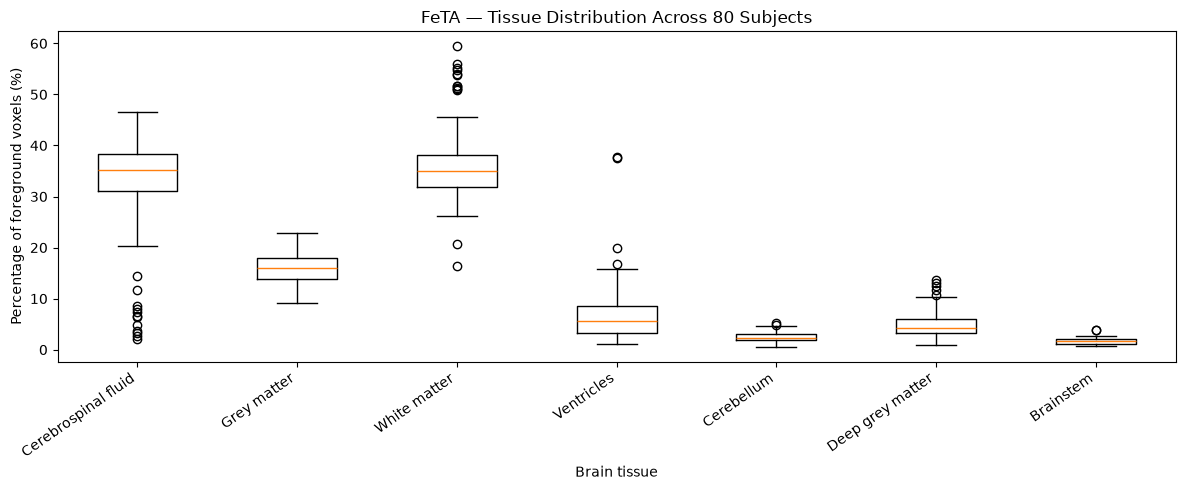

In [12]:

# Exclude background
foreground_df = labels_df[labels_df["label"] != 0]

# Prepare class distributions
tissues = list(FETA_LABELS.values())[1:]

distributions = [
    foreground_df.loc[
        foreground_df["tissue"] == tissue,
        "foreground_percentage"
    ].dropna().values
    for tissue in tissues
]

plt.figure(figsize=(12, 5))

plt.boxplot(distributions, tick_labels=tissues)

plt.title("FeTA — Tissue Distribution Across 80 Subjects")
plt.xlabel("Brain tissue")
plt.ylabel("Percentage of foreground voxels (%)")

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


In [13]:

# Compare average foreground tissue proportions
comparison_df = (
    foreground_df.groupby(["reconstruction", "tissue"])[
        "foreground_percentage"
    ]
    .mean()
    .unstack("reconstruction")
)

display(comparison_df.round(2))


reconstruction,irtk,mial
tissue,,
Brainstem,2.21,1.18
Cerebellum,2.16,2.67
Cerebrospinal fluid,34.66,28.14
Deep grey matter,3.18,6.75
Grey matter,17.48,14.59
Ventricles,7.06,7.25
White matter,33.24,39.42



### Findings — Dataset-Wide Tissue Distribution

Analysis of all 80 FeTA segmentation masks reveals:

- **All seven brain tissue classes are present** in every subject.
- **Strong class imbalance:** Background occupies approximately 90.7% of the volume, while brainstem and cerebellum are the smallest classes.
- **Anatomical variability:** Tissue proportions vary across subjects, particularly for CSF, white matter, and ventricles.
- **Reconstruction-group differences:** MIAL and IRTK show different average tissue proportions (e.g., white matter: 39.4% vs. 33.2% of foreground voxels).

**Implications for model development:**
- Use per-class segmentation metrics rather than relying on global voxel accuracy.
- Consider imbalance-aware loss functions and foreground sampling.
- Account for differences between reconstruction groups during evaluation.

**Limitation:** Differences between subjects or reconstruction groups may reflect gestational age, pathology, or annotation variability rather than reconstruction effects alone.

**Next step:** Explore subject metadata (gestational age and pathology) to better understand dataset variability.



### 3.3 Subject Metadata Analysis

**Objectives:**
- Explore the gestational age distribution.
- Identify neurotypical and pathological subjects.
- Compare subject characteristics across reconstruction methods.
- Investigate potential factors influencing anatomical variability.

**Why is this important?**

Brain anatomy changes rapidly during fetal development, and pathologies may affect tissue volumes.

Understanding the subject population is essential for designing representative training, validation, and test splits, and for interpreting segmentation performance across different groups.


In [14]:

# Locate the subject metadata file
metadata_path = DATA_DIR / "participants.tsv"

print("Metadata file exists:", metadata_path.exists())

if metadata_path.exists():
    participants_df = pd.read_csv(metadata_path, sep="\t")

    print("\nAvailable columns:")
    print(participants_df.columns.tolist())

    print("\nNumber of participants:", len(participants_df))

    display(participants_df.head())
else:
    print("participants.tsv not found. Check the dataset documentation.")


Metadata file exists: True

Available columns:
['participant_id', 'pathology', 'gestational_age']

Number of participants: 80


,participant_id,pathology,gestational_age
0,sub-001,Pathological,27.9
1,sub-002,Pathological,28.2
2,sub-003,Pathological,27.4
3,sub-004,Pathological,25.5
4,sub-005,Pathological,22.6


In [15]:

# Check missing metadata
print("Missing values:")
print(participants_df.isna().sum())

# Gestational age statistics
print("\nGestational age statistics (weeks):")
display(participants_df["gestational_age"].describe().round(2))

# Pathology distribution
print("\nPathology distribution:")
display(participants_df["pathology"].value_counts())


Missing values:
participant_id     0
pathology          0
gestational_age    0
dtype: int64

Gestational age statistics (weeks):


count    80.00
mean     27.03
std       3.60
min      20.00
25%      23.98
50%      27.25
75%      29.12
max      34.80
Name: gestational_age, dtype: float64


Pathology distribution:


pathology
Pathological    49
Neurotypical    31
Name: count, dtype: int64

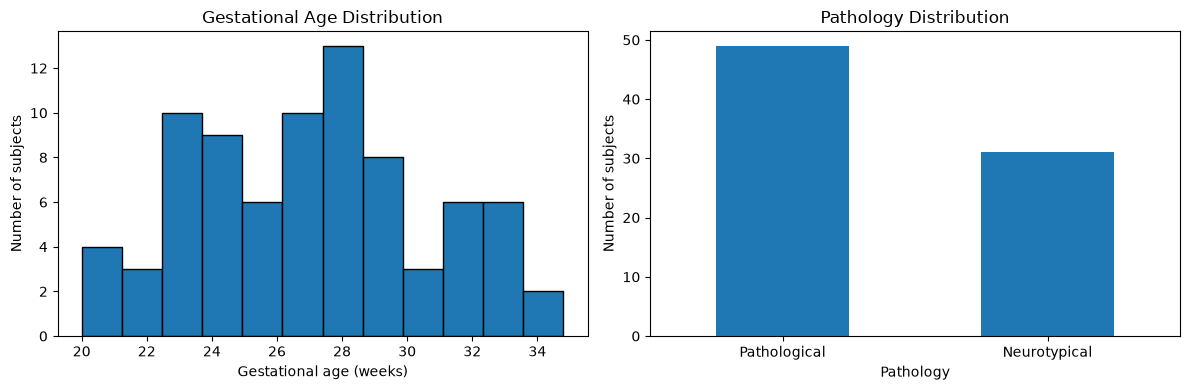

In [16]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Gestational age distribution
axes[0].hist(
    participants_df["gestational_age"].dropna(),
    bins=12,
    edgecolor="black"
)
axes[0].set_title("Gestational Age Distribution")
axes[0].set_xlabel("Gestational age (weeks)")
axes[0].set_ylabel("Number of subjects")

# Pathology distribution
participants_df["pathology"].value_counts().plot(
    kind="bar",
    ax=axes[1]
)
axes[1].set_title("Pathology Distribution")
axes[1].set_xlabel("Pathology")
axes[1].set_ylabel("Number of subjects")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


In [17]:

# Merge subject metadata with MRI properties
analysis_df = dataset_df.merge(
    participants_df,
    left_on="subject",
    right_on="participant_id",
    how="left",
    validate="one_to_one"
)

# Check that every subject has metadata
print("Subjects with missing metadata:")
print(analysis_df["gestational_age"].isna().sum())

# Compare pathology across reconstruction methods
print("\nPathology by reconstruction method:")
display(pd.crosstab(
    analysis_df["reconstruction"],
    analysis_df["pathology"]
))

# Compare gestational ages across reconstruction methods
print("\nGestational age by reconstruction method:")
display(
    analysis_df.groupby("reconstruction")["gestational_age"]
    .describe()
    .round(2)
)


Subjects with missing metadata:
0

Pathology by reconstruction method:


pathology,Neurotypical,Pathological
reconstruction,,
irtk,16,24
mial,15,25



Gestational age by reconstruction method:


,count,mean,std,min,25%,50%,75%,max
reconstruction,,,,,,,,
irtk,40.0,27.13,3.97,20.1,23.82,27.3,29.30,34.8
mial,40.0,26.93,3.23,20.0,24.28,27.1,28.78,33.4



### Findings — Subject Metadata Analysis

Analysis of the 80 FeTA subjects reveals:

- **Complete metadata:** No missing gestational age or pathology information.
- **Gestational age:** 20–34.8 weeks (mean: 27.03 weeks).
- **Pathology distribution:** 49 pathological and 31 neurotypical subjects.
- **Comparable reconstruction groups:**
  - IRTK: 24 pathological, 16 neurotypical; mean age 27.13 weeks.
  - MIAL: 25 pathological, 15 neurotypical; mean age 26.93 weeks.

**Implications for model development:**
- Consider gestational age and pathology when designing train/validation/test splits.
- Evaluate model performance across developmental stages and pathology groups.
- Track reconstruction method to investigate potential domain-specific performance differences.

**Limitation:** Similar group-level age and pathology distributions do not establish that reconstruction methods cause the observed differences in tissue proportions.



### 3.4 Data Quality Checks

**Objectives:**
- Detect NaN or infinite values in MRI volumes.
- Identify empty or constant MRI volumes.
- Verify that segmentation masks contain integer labels.
- Check for empty segmentation masks.
- Identify subjects requiring further inspection.

**Why is this important?**

Invalid values or corrupted images can cause training failures, unstable losses, or misleading evaluation results.

These checks help identify potentially problematic subjects before preprocessing and model training.


In [18]:

# Expected FeTA segmentation labels
EXPECTED_LABELS = set(range(8))

quality_records = []

for mri_path in mri_files:

    # Find corresponding segmentation
    seg_path = mri_path.with_name(
        mri_path.name.replace("_T2w.nii.gz", "_dseg.nii.gz")
    )

    # Load MRI and segmentation
    _, mri = load_nifti(mri_path)
    _, seg = load_nifti(seg_path, is_segmentation=True)

    # Run quality checks
    quality = check_volume_quality(mri, seg, EXPECTED_LABELS)

    quality_records.append({
        "subject": mri_path.parent.parent.name,
        "reconstruction": mri_path.name.split("_rec-")[1].split("_")[0],
        **quality,
    })

quality_df = pd.DataFrame(quality_records)

display(quality_df.head())


,subject,reconstruction,mri_nan,mri_inf,mri_constant,seg_nan,seg_inf,seg_non_integer,seg_empty,unexpected_labels
0,sub-001,mial,0,0,False,0,0,False,False,[]
1,sub-002,mial,0,0,False,0,0,False,False,[]
2,sub-003,mial,0,0,False,0,0,False,False,[]
3,sub-004,mial,0,0,False,0,0,False,False,[]
4,sub-005,mial,0,0,False,0,0,False,False,[]


In [19]:

# Summarize basic data quality checks
print("Total subjects checked:", len(quality_df))

print("\nMRI issues:")
print("NaN voxels:", quality_df["mri_nan"].sum())
print("Infinite voxels:", quality_df["mri_inf"].sum())
print("Constant MRI volumes:", quality_df["mri_constant"].sum())

print("\nSegmentation issues:")
print("NaN voxels:", quality_df["seg_nan"].sum())
print("Infinite voxels:", quality_df["seg_inf"].sum())
print("Non-integer label volumes:", quality_df["seg_non_integer"].sum())
print("Empty segmentation masks:", quality_df["seg_empty"].sum())

print(
    "Volumes with unexpected labels:",
    quality_df["unexpected_labels"].apply(bool).sum()
)

# Identify subjects with quality issues
issue_columns = [
    "mri_nan", "mri_inf", "mri_constant",
    "seg_nan", "seg_inf", "seg_non_integer",
    "seg_empty"
]

has_issues = (
    quality_df[issue_columns].astype(bool).any(axis=1)
    | quality_df["unexpected_labels"].apply(bool)
)

problematic_subjects = quality_df[has_issues]

print("\nSubjects requiring inspection:", len(problematic_subjects))
display(problematic_subjects)


Total subjects checked: 80

MRI issues:
NaN voxels: 0
Infinite voxels: 0
Constant MRI volumes: 0

Segmentation issues:
NaN voxels: 0
Infinite voxels: 0
Non-integer label volumes: 0
Empty segmentation masks: 0
Volumes with unexpected labels: 0

Subjects requiring inspection: 0


,subject,reconstruction,mri_nan,mri_inf,mri_constant,seg_nan,seg_inf,seg_non_integer,seg_empty,unexpected_labels



### Findings — Data Quality Checks

All 80 FeTA MRI–segmentation pairs passed the automated quality checks:

- No NaN or infinite values were detected.
- No constant MRI volumes or empty segmentation masks were found.
- All segmentation masks contain valid integer labels (0–7).
- No subjects were flagged for numerical data quality issues.

**Conclusion:** No numerical data quality problems were identified that would prevent proceeding with preprocessing.

**Limitation:** These checks do not assess MRI artifacts, image sharpness, or anatomical annotation accuracy. Further visual inspection may still be necessary.



## 4. EDA Summary and Next Steps

### Key Findings

- **Dataset:** 80 fetal MRI volumes with corresponding segmentation masks.
- **Reconstruction:** 40 MIAL and 40 IRTK volumes.
- **Image properties:** All volumes have shape (256, 256, 256), but voxel spacing and orientation differ between reconstruction methods.
- **Segmentation:** All seven brain tissue classes are present, with substantial class imbalance.
- **Metadata:** Gestational ages range from 20 to 34.8 weeks; 49 subjects are pathological and 31 neurotypical.
- **Data quality:** No numerical issues or meaningful MRI–mask affine mismatches were detected.

### Preprocessing Considerations

Based on these findings, the following steps should be investigated:

1. Standardizing MRI and segmentation orientations.
2. Resampling volumes to a consistent voxel spacing if required.
3. Normalizing MRI intensities.
4. Considering class imbalance during training and evaluation.

### Next Steps

- Inspect the pretrained foundation model and its preprocessing requirements.
- Define a consistent preprocessing pipeline for FeTA and BOBs.
- Design subject-level training, validation, and test splits.
- Prepare the segmentation training and evaluation pipelines.

**Note:** No preprocessing transformations or model training have been performed in this notebook.
